# Cerro Alegre — DeepForest y Mask R-CNN

## 1. Preparación compartida

### 1.1 Instalación de dependencias

In [1]:
!pip -q install pycocotools rasterio geopandas pyogrio shapely pandas matplotlib tqdm opencv-python-headless

print("Dependencias listas")

Dependencias listas


### 1.1 Configuración general y rutas

In [2]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
from rasterio.plot import show
from shapely.geometry import box

from google.colab import drive
drive.mount("/content/drive")

BASE = Path("/content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega")
DATOS = BASE / "datos"
DIRECTORIO_RESULTADOS = BASE / "resultados"
DIRECTORIO_RESULTADOS.mkdir(parents=True, exist_ok=True)

# Se buscan los archivos fuente.
RUTA_TIF = DATOS / "Cerro_Alegre_Censo_Clip.tif"
RUTA_SHP = DATOS / "Censo_CerroAlegre_parcelas_12-15-16.shp"
RUTA_PREPARADA = DATOS / "Cerro_Alegre_Censo_Clip_uint8_global.tif"
RUTA_MASCARA = DATOS / "Cerro_Alegre_mascara_valida.tif"

# Parámetros exclusivos de DeepForest.
PATCH_SIZE = 400
PATCH_OVERLAP = 0.30
SCORE_THRESHOLD = 0.15
IOU_THRESHOLD = 0.15

print("Raster original:", RUTA_TIF)
print("Censo:", RUTA_SHP)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Raster original: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/datos/Cerro_Alegre_Censo_Clip.tif
Censo: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/datos/Censo_CerroAlegre_parcelas_12-15-16.shp


### 1.2 Máscara de cobertura válida

In [3]:
# Identifica los píxeles con datos en las tres bandas de la ortofoto original.
# Se guarda en disco y se utiliza posteriormente para filtrar puntos censales y detecciones.
with rasterio.open(RUTA_TIF) as src:
    img = src.read([1, 2, 3]).astype(np.float32)
    nodata = src.nodata
    if nodata is None:
        raise ValueError("El raster original no tiene NoData definido.")

    mascara_valida = np.all(~np.isclose(img, nodata), axis=0)
    perfil = src.profile.copy()
    perfil.update(count=1, dtype="uint8", nodata=0)

with rasterio.open(RUTA_MASCARA, "w", **perfil) as dst:
    dst.write(mascara_valida.astype("uint8"), 1)

print("NoData original:", nodata)
print("Píxeles totales:", mascara_valida.size)
print("Píxeles válidos:", mascara_valida.sum())
print("Cobertura válida (%):", round(mascara_valida.mean() * 100, 2))
print("Máscara guardada en:", RUTA_MASCARA)


NoData original: -10000.0
Píxeles totales: 13370554
Píxeles válidos: 5020636
Cobertura válida (%): 37.55
Máscara guardada en: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/datos/Cerro_Alegre_mascara_valida.tif


### 1.3 Preparación radiométrica de la ortofoto

In [4]:
# Convierte las tres bandas a uint8 mediante percentiles globales.
with rasterio.open(RUTA_TIF) as src:
    img = src.read([1, 2, 3]).astype(np.float32)
    perfil = src.profile.copy()

valores_validos = img[:, mascara_valida]
p2_global = np.percentile(valores_validos, 2)
p98_global = np.percentile(valores_validos, 98)
if p98_global <= p2_global:
    raise ValueError("Percentiles inválidos para preparar la imagen.")

rgb_scaled = np.clip((img - p2_global) / (p98_global - p2_global), 0, 1)
rgb8 = (rgb_scaled * 255).astype(np.uint8)
rgb8[:, ~mascara_valida] = 0

perfil.update(dtype="uint8", count=3, nodata=0)
with rasterio.open(RUTA_PREPARADA, "w", **perfil) as dst:
    dst.write(rgb8)

print("Imagen preparada:", RUTA_PREPARADA)


Imagen preparada: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/datos/Cerro_Alegre_Censo_Clip_uint8_global.tif


### 1.4 Comprobación de alineación espacial

In [5]:
# Control de compatibilidad espacial entre raster original, raster preparado y máscara.

with rasterio.open(RUTA_TIF) as src_orig, \
     rasterio.open(RUTA_PREPARADA) as src_prep, \
     rasterio.open(RUTA_MASCARA) as src_mask:

    print("Mismo CRS original/preparado:", src_orig.crs == src_prep.crs)
    print("Mismo tamaño original/preparado:",
          (src_orig.width, src_orig.height) == (src_prep.width, src_prep.height))
    print("Mismo transform original/preparado:",
          src_orig.transform == src_prep.transform)

    print("Mismo CRS original/máscara:", src_orig.crs == src_mask.crs)
    print("Mismo tamaño original/máscara:",
          (src_orig.width, src_orig.height) == (src_mask.width, src_mask.height))
    print("Mismo transform original/máscara:",
          src_orig.transform == src_mask.transform)


Mismo CRS original/preparado: True
Mismo tamaño original/preparado: True
Mismo transform original/preparado: True
Mismo CRS original/máscara: True
Mismo tamaño original/máscara: True
Mismo transform original/máscara: True


### 1.5 Censo evaluable

In [6]:
# Se leen los puntos censales, se transforman al CRS del raster si corresponde y se conservan solamente aquellos ubicados en píxeles válidos.
# Este conjunto será la referencia para ambas evaluaciones censales.
censo_total = gpd.read_file(RUTA_SHP).copy().reset_index(drop=True)

with rasterio.open(RUTA_MASCARA) as src:
    if censo_total.crs is None:
        raise ValueError("El censo no tiene CRS definido.")
    if censo_total.crs != src.crs:
        censo_total = censo_total.to_crs(src.crs)
    coords = [(p.x, p.y) for p in censo_total.geometry]
    valores = np.array([v[0] for v in src.sample(coords)])

censo_total["imagen_valida"] = valores == 1
censo_eval = censo_total.loc[censo_total["imagen_valida"]].copy().reset_index(drop=True)
censo_eval["id_punto"] = np.arange(len(censo_eval))

# Alias para las secciones originales, evitando recalcular los datos.
gdf_puntos = censo_total
gdf_evaluable = censo_eval
censo_completo = censo_total
censo_evaluable = censo_eval

print("Censo original:", len(censo_total))
print("Censo evaluable:", len(censo_eval))
print("Excluidos:", len(censo_total) - len(censo_eval))


Censo original: 2917
Censo evaluable: 2682
Excluidos: 235


## 2. DeepForest

Se utiliza el modelo preentrenado de DeepForest. Sus cajas se convierten a coordenadas geográficas, se filtran por cobertura válida y se comparan con el censo fuente.

### 2.1 Carga del modelo y parámetros

In [7]:
# Si DeepForest no está instalado
#!pip install deepforest

# Los parámetros PATCH_SIZE, PATCH_OVERLAP, SCORE_THRESHOLD e IOU_THRESHOLD se definieron en la configuración inicial.
from deepforest import main

modelo_deepforest = main.deepforest()

modelo_deepforest.load_model(
    model_name="weecology/deepforest-tree",
    revision="main"
)

print("Modelo DeepForest cargado.")


config.json:   0%|          | 0.00/235 [00:00<?, ?B/s]

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 162MB/s]


model.safetensors: reconstructing file:   0%|          |  0.00B /  129MB            

model.safetensors: downloading bytes:           |  0.00B            

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Modelo DeepForest cargado.


### 2.2 Inferencia sobre la ortofoto

In [8]:
# La imagen se recorre por teselas. Se descartan las detecciones donde la confianza sea inferior al umbral configurado.
pred_final = modelo_deepforest.predict_tile(
    path=str(RUTA_PREPARADA),
    patch_size=PATCH_SIZE,
    patch_overlap=PATCH_OVERLAP,
    iou_threshold=IOU_THRESHOLD
)

pred_final = pred_final[
    pred_final["score"] >= SCORE_THRESHOLD
].copy().reset_index(drop=True)

print("Predicciones después de score threshold:", len(pred_final))


INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Output()

/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


5423 predictions in overlapping windows, applying non-max suppression
2721 predictions kept after non-max suppression
Predicciones después de score threshold: 2659


### 2.3 Georreferenciación de las cajas

In [9]:
# Se transforman las coordenadas de píxel a coordenadas del sistema de referencia del raster.
with rasterio.open(RUTA_PREPARADA) as src:
    transform_full = src.transform
    crs_full = src.crs

geometrias = []

for _, row in pred_final.iterrows():

    x1, y1 = rasterio.transform.xy(
        transform_full,
        row["ymin"],
        row["xmin"],
        offset="ul"
    )

    x2, y2 = rasterio.transform.xy(
        transform_full,
        row["ymax"],
        row["xmax"],
        offset="ul"
    )

    geometrias.append(
        box(
            min(x1, x2),
            min(y1, y2),
            max(x1, x2),
            max(y1, y2)
        )
    )

pred_final_geo = gpd.GeoDataFrame(
    pred_final.copy(),
    geometry=geometrias,
    crs=crs_full
).reset_index(drop=True)

pred_final_geo["id_box"] = range(len(pred_final_geo))

print("CRS predicciones:", pred_final_geo.crs)
print("Predicciones georreferenciadas:", len(pred_final_geo))


CRS predicciones: PROJCS["WGS 84 / UTM zone 21S",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-57],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",10000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32721"]]
Predicciones georreferenciadas: 2659


### 2.4 Filtrado por cobertura válida

In [10]:
# Se conserva una detección cuando el centro de su caja cae dentro de la máscara válida compartida.
centros_pred = pred_final_geo.geometry.centroid

with rasterio.open(RUTA_MASCARA) as src_mask:

    coords_pred = [
        (geom.x, geom.y)
        for geom in centros_pred
    ]

    valores_pred = np.array([
        v[0]
        for v in src_mask.sample(coords_pred)
    ])

pred_final_geo["imagen_valida"] = valores_pred == 1

pred_final_evaluable = (
    pred_final_geo[pred_final_geo["imagen_valida"]]
    .copy()
    .reset_index(drop=True)
)

pred_final_evaluable["id_box"] = range(len(pred_final_evaluable))

print("Predicciones totales:", len(pred_final_geo))
print("Predicciones evaluables:", len(pred_final_evaluable))
print("Predicciones excluidas por NoData:",
      len(pred_final_geo) - len(pred_final_evaluable))


Predicciones totales: 2659
Predicciones evaluables: 2640
Predicciones excluidas por NoData: 19


### 2.5 Correspondencia con el censo

In [11]:
# Primero se identifican las relaciones entre puntos censales y cajas que los contienen.
# Después se resuelven las coincidencias para que cada punto y cada detección participen como máximo en un emparejamiento.

# Preparar puntos censales y detecciones para la correspondencia espacial.
gt_global = gdf_evaluable.copy().reset_index(drop=True)
gt_global["id_punto"] = range(len(gt_global))

pred_global = pred_final_evaluable.copy().reset_index(drop=True)
pred_global["id_box"] = range(len(pred_global))

join_global = gpd.sjoin(
    gt_global[["id_punto", "geometry"]],
    pred_global[["id_box", "score", "geometry"]],
    how="inner",
    predicate="within"
)

print("Relaciones punto-caja antes del matching 1:1:", len(join_global))


Relaciones punto-caja antes del matching 1:1: 2378


In [12]:
# Emparejar puntos y cajas de forma uno a uno, por distancia al centro.
if len(join_global) > 0:

    centros = (
        pred_global
        .set_index("id_box")
        .geometry
        .centroid
    )

    puntos_dict = (
        gt_global
        .set_index("id_punto")
        .geometry
        .to_dict()
    )

    join_global = join_global.copy()

    join_global["dist_centro"] = join_global.apply(
        lambda r:
            puntos_dict[r["id_punto"]].distance(
                centros.loc[r["id_box"]]
            ),
        axis=1
    )

    join_global = join_global.sort_values("dist_centro")

    puntos_usados = set()
    boxes_usadas = set()
    matches_global = []

    for _, row in join_global.iterrows():

        p = int(row["id_punto"])
        b = int(row["id_box"])

        if p not in puntos_usados and b not in boxes_usadas:

            puntos_usados.add(p)
            boxes_usadas.add(b)
            matches_global.append((p, b))

else:
    matches_global = []

TP_global = len(matches_global)

N_real_global = len(gt_global)
N_pred_global = len(pred_global)

FP_global = N_pred_global - TP_global
FN_global = N_real_global - TP_global

precision_global = (
    TP_global / N_pred_global
    if N_pred_global > 0 else 0
)

recall_global = (
    TP_global / N_real_global
    if N_real_global > 0 else 0
)

f1_global = (
    2 * precision_global * recall_global /
    (precision_global + recall_global)
    if (precision_global + recall_global) > 0
    else 0
)

error_conteo_global = (
    (N_pred_global - N_real_global) /
    N_real_global * 100
    if N_real_global > 0
    else np.nan
)

print("\n==========================================")
print("RESULTADO GLOBAL — CERRO ALEGRE")
print("==========================================")
print("Árboles censados totales:", len(gdf_puntos))
print("Árboles reales evaluables:", N_real_global)
print("Árboles excluidos por NoData:",
      len(gdf_puntos) - N_real_global)
print("Predicciones evaluables:", N_pred_global)

print("\nTP:", TP_global)
print("FP:", FP_global)
print("FN:", FN_global)

print("\nPrecision:", round(precision_global, 3))
print("Recall:", round(recall_global, 3))
print("F1:", round(f1_global, 3))
print("Error de conteo:", round(error_conteo_global, 2), "%")



RESULTADO GLOBAL — CERRO ALEGRE
Árboles censados totales: 2917
Árboles reales evaluables: 2682
Árboles excluidos por NoData: 235
Predicciones evaluables: 2640

TP: 2340
FP: 300
FN: 342

Precision: 0.886
Recall: 0.872
F1: 0.879
Error de conteo: -1.57 %


### 2.6 Identificación de TP, FP y FN

In [13]:
# Se separan los puntos detectados, los árboles omitidos y las detecciones sin correspondencia para su análisis visual.
ids_tp_punto = {p for p, b in matches_global}
ids_tp_box = {b for p, b in matches_global}

gt_tp = gt_global[
    gt_global["id_punto"].isin(ids_tp_punto)
].copy()

gt_fn = gt_global[
    ~gt_global["id_punto"].isin(ids_tp_punto)
].copy()

pred_fp = pred_global[
    ~pred_global["id_box"].isin(ids_tp_box)
].copy()

print("TP:", len(gt_tp))
print("FN:", len(gt_fn))
print("FP:", len(pred_fp))


TP: 2340
FN: 342
FP: 300


### 2.7 Visualización y exportación

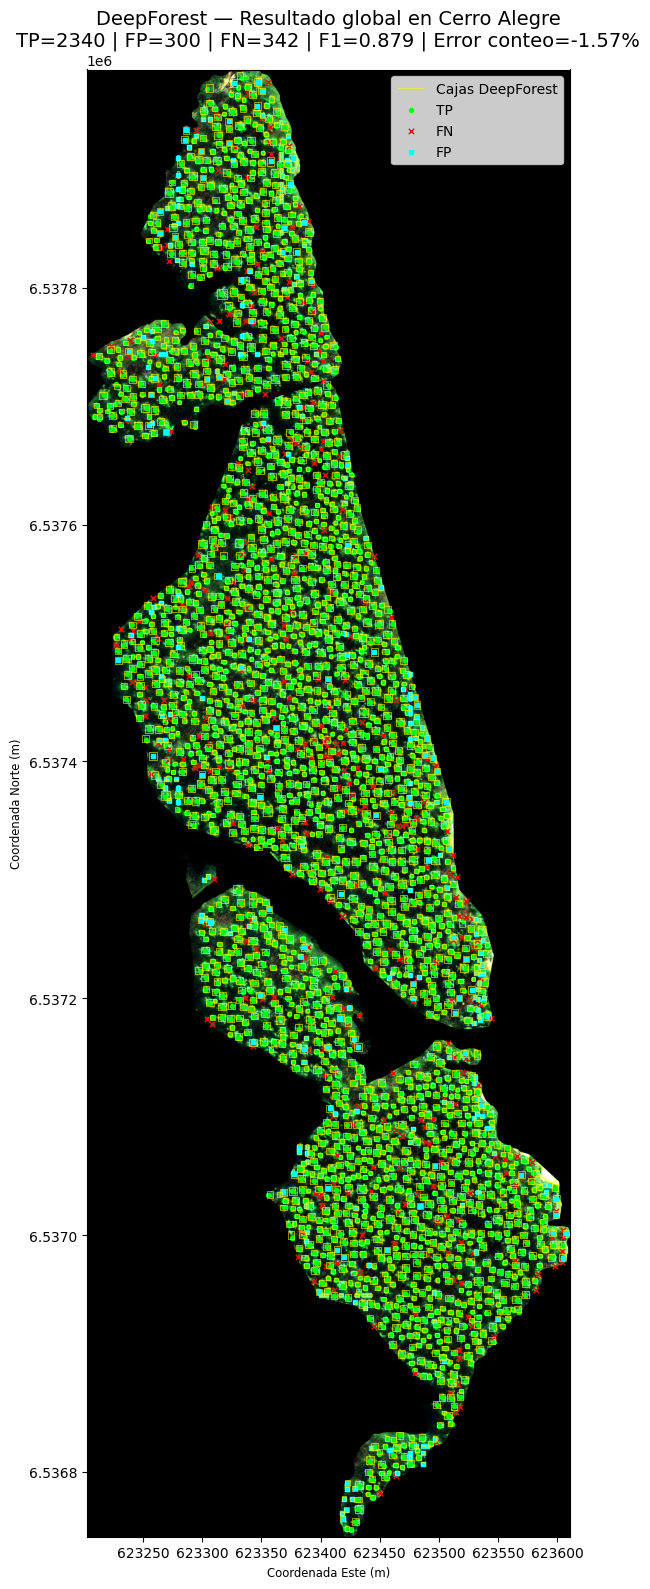

Figura guardada en: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/resultados/DeepForest_CerroAlegre_resultado_global.png


In [14]:
# Se presenta el mapa de resultados y se guardan las métricas y las detecciones evaluables.
with rasterio.open(RUTA_PREPARADA) as src:

    fig, ax = plt.subplots(figsize=(14, 16))

    show(src, ax=ax)

    # Todas las cajas evaluables de DeepForest
    pred_global.boundary.plot(
        ax=ax,
        color="yellow",
        linewidth=0.6,
        alpha=0.65,
        label="Cajas DeepForest"
    )

    # Árboles correctamente detectados
    gt_tp.plot(
        ax=ax,
        color="lime",
        marker="o",
        markersize=8,
        label="TP"
    )

    # Árboles omitidos
    gt_fn.plot(
        ax=ax,
        color="red",
        marker="x",
        markersize=15,
        linewidth=1,
        label="FN"
    )

    # Falsos positivos: centro de la caja
    if len(pred_fp) > 0:
        pred_fp.geometry.centroid.plot(
            ax=ax,
            color="cyan",
            marker="s",
            markersize=10,
            label="FP"
        )

    ax.set_title(
        "DeepForest — Resultado global en Cerro Alegre\n"
        f"TP={TP_global} | FP={FP_global} | FN={FN_global} | "
        f"F1={f1_global:.3f} | Error conteo={error_conteo_global:.2f}%",
        fontsize=14
    )

    ax.set_xlabel("Coordenada Este (m)")
    ax.set_ylabel("Coordenada Norte (m)")
    ax.legend(loc="upper right")

    plt.tight_layout()

    ruta_figura = os.path.join(
        DIRECTORIO_RESULTADOS,
        "DeepForest_CerroAlegre_resultado_global.png"
    )

    plt.savefig(
        ruta_figura,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("Figura guardada en:", ruta_figura)


In [15]:
# Tabla resumen
resumen_global = pd.DataFrame([{
    "sitio": "Cerro Alegre",
    "N_censo_total": len(gdf_puntos),
    "N_real_evaluable": N_real_global,
    "N_pred_evaluable": N_pred_global,
    "TP": TP_global,
    "FP": FP_global,
    "FN": FN_global,
    "Precision": precision_global,
    "Recall": recall_global,
    "F1": f1_global,
    "Error_conteo_%": error_conteo_global,
    "patch_size": PATCH_SIZE,
    "patch_overlap": PATCH_OVERLAP,
    "score_threshold": SCORE_THRESHOLD,
    "iou_threshold": IOU_THRESHOLD
}])

ruta_resumen = os.path.join(
    DIRECTORIO_RESULTADOS,
    "DeepForest_CerroAlegre_resumen_global.csv"
)

ruta_pred = os.path.join(
    DIRECTORIO_RESULTADOS,
    "DeepForest_CerroAlegre_predicciones_evaluables.gpkg"
)

resumen_global.to_csv(ruta_resumen, index=False)

# Se quita la columna auxiliar de centroides si existe antes de guardar
pred_guardar = pred_global.drop(
    columns=["centro"],
    errors="ignore"
).copy()

pred_guardar.to_file(
    ruta_pred,
    layer="predicciones",
    driver="GPKG"
)

print("Resumen:", ruta_resumen)
print("Predicciones:", ruta_pred)

resumen_global


Resumen: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/resultados/DeepForest_CerroAlegre_resumen_global.csv
Predicciones: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/resultados/DeepForest_CerroAlegre_predicciones_evaluables.gpkg


,sitio,N_censo_total,N_real_evaluable,N_pred_evaluable,TP,FP,FN,Precision,Recall,F1,Error_conteo_%,patch_size,patch_overlap,score_threshold,iou_threshold
0,Cerro Alegre,2917,2682,2640,2340,300,342,0.886364,0.872483,0.879369,-1.565996,400,0.3,0.15,0.15


### 2.8 Revisión visual de errores

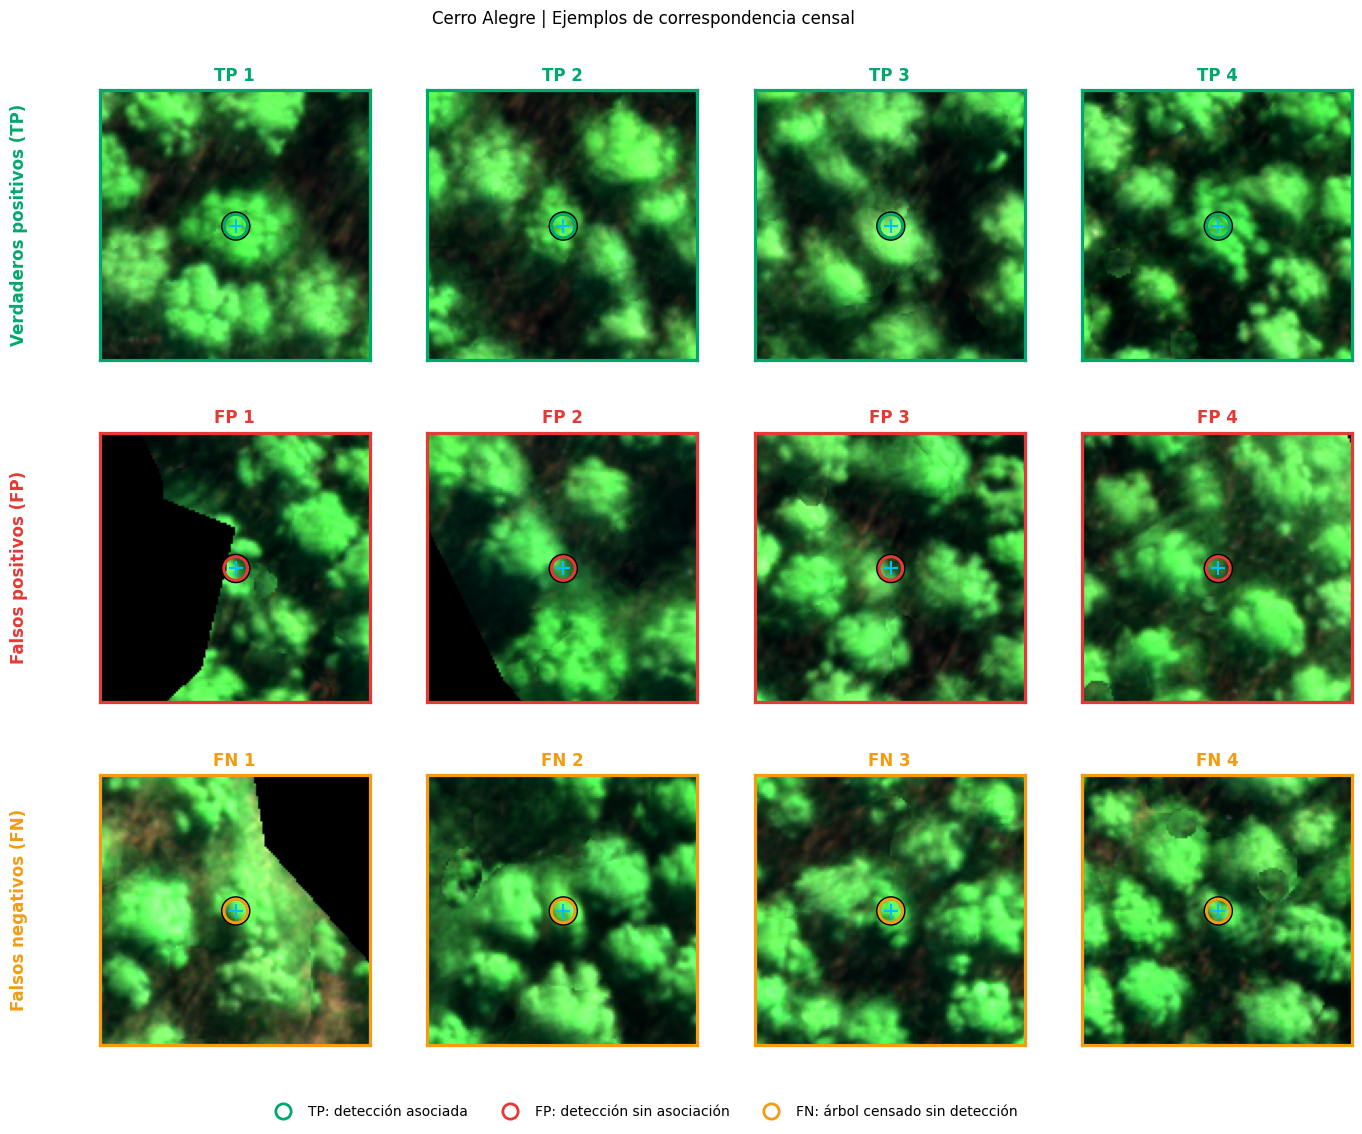

In [16]:

import rasterio
import matplotlib.pyplot as plt
import numpy as np
from rasterio.windows import Window
from matplotlib.lines import Line2D

PATCH_VIS = 128

COLORES = {
    "TP": "#00A86B",
    "FP": "#E53935",
    "FN": "#F39C12"
}

def extraer_patch_por_coordenada(src, x, y, size=128):

    row, col = src.index(x, y)
    half = size // 2

    # Mantener el punto centrado, incluso cerca de bordes
    row_off = row - half
    col_off = col - half

    window = Window(col_off, row_off, size, size)

    patch = src.read(
        [1, 2, 3],
        window=window,
        boundless=True,
        fill_value=0
    )

    return np.moveaxis(patch, 0, -1)


def porcentaje_valido(patch):
    return np.mean(np.any(patch != 0, axis=2))


# Mantener la selección original de TP y FN
muestra_tp = gt_tp.sample(n=4, random_state=42)
muestra_fn = gt_fn.sample(n=4, random_state=42)

# Mantener los primeros dos FP originales
muestra_fp_original = pred_fp.sample(n=4, random_state=42)
fp_fijos = muestra_fp_original.iloc[:2]

# Buscar nuevos FP con mayor cobertura de imagen
candidatos = pred_fp.drop(
    index=muestra_fp_original.index
).sample(
    frac=1,
    random_state=123
)

nuevos_fp = []

with rasterio.open(RUTA_PREPARADA) as src:

    for idx, row in candidatos.iterrows():

        centro = row.geometry.centroid

        patch = extraer_patch_por_coordenada(
            src, centro.x, centro.y,
            size=PATCH_VIS
        )

        if porcentaje_valido(patch) >= 0.98:
            nuevos_fp.append(idx)

        if len(nuevos_fp) == 2:
            break

if len(nuevos_fp) < 2:
    raise ValueError(
        "No se encontraron dos FP adicionales con "
        "al menos 98 % de cobertura válida."
    )

muestra_fp = pred_fp.loc[
    list(fp_fijos.index) + nuevos_fp
]


def mostrar_figura_tesis():

    grupos = [
        ("TP", muestra_tp, False),
        ("FP", muestra_fp, True),
        ("FN", muestra_fn, False)
    ]

    fig, axes = plt.subplots(
        3, 4,
        figsize=(15, 11.5)
    )

    fig.suptitle(
        "Cerro Alegre | Ejemplos de correspondencia censal",
        fontsize=12,
        y=0.99
    )

    with rasterio.open(RUTA_PREPARADA) as src:

        for fila, (categoria, muestra, usar_centroide) in enumerate(grupos):

            color = COLORES[categoria]

            for columna, (_, registro) in enumerate(muestra.iterrows()):

                ax = axes[fila, columna]

                geom = (
                    registro.geometry.centroid
                    if usar_centroide
                    else registro.geometry
                )

                patch = extraer_patch_por_coordenada(
                    src,
                    geom.x,
                    geom.y,
                    size=PATCH_VIS
                )

                ax.imshow(patch)

                centro = PATCH_VIS / 2

                # Círculo de identificación
                ax.scatter(
                    centro, centro,
                    s=340,
                    facecolors="none",
                    edgecolors="black",
                    linewidths=2.8,
                    zorder=5
                )

                ax.scatter(
                    centro, centro,
                    s=290,
                    facecolors="none",
                    edgecolors=color,
                    linewidths=2.2,
                    zorder=6
                )

                # Cruz central
                ax.scatter(
                    centro, centro,
                    marker="+",
                    s=110,
                    color="#00BFFF",
                    linewidths=1.5,
                    zorder=7
                )

                ax.set_title(
                    f"{categoria} {columna + 1}",
                    fontsize=12,
                    fontweight="bold",
                    color=color,
                    pad=7
                )

                ax.set_xticks([])
                ax.set_yticks([])

                # Borde del color de la categoría
                for spine in ax.spines.values():
                    spine.set_visible(True)
                    spine.set_color(color)
                    spine.set_linewidth(2.3)

    nombres = {
        "TP": "Verdaderos positivos (TP)",
        "FP": "Falsos positivos (FP)",
        "FN": "Falsos negativos (FN)"
    }

    for fila, categoria in enumerate(["TP", "FP", "FN"]):

        axes[fila, 0].annotate(
            nombres[categoria],
            xy=(-0.30, 0.5),
            xycoords="axes fraction",
            rotation=90,
            ha="center",
            va="center",
            fontsize=12,
            fontweight="bold",
            color=COLORES[categoria]
        )

    leyenda = [
        Line2D(
            [0], [0],
            marker="o",
            color="none",
            markerfacecolor="none",
            markeredgecolor=COLORES["TP"],
            markeredgewidth=2,
            markersize=11,
            label="TP: detección asociada"
        ),
        Line2D(
            [0], [0],
            marker="o",
            color="none",
            markerfacecolor="none",
            markeredgecolor=COLORES["FP"],
            markeredgewidth=2,
            markersize=11,
            label="FP: detección sin asociación"
        ),
        Line2D(
            [0], [0],
            marker="o",
            color="none",
            markerfacecolor="none",
            markeredgecolor=COLORES["FN"],
            markeredgewidth=2,
            markersize=11,
            label="FN: árbol censado sin detección"
        )
    ]

    fig.legend(
        handles=leyenda,
        loc="lower center",
        ncol=3,
        frameon=False,
        fontsize=10,
        bbox_to_anchor=(0.5, 0.015)
    )

    plt.subplots_adjust(
        left=0.13,
        right=0.98,
        top=0.92,
        bottom=0.09,
        hspace=0.27,
        wspace=0.12
    )

    fig.savefig(
        "Cerro_Alegre_TP_FP_FN_Tesis.png",
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    fig.savefig(
        "Cerro_Alegre_TP_FP_FN_Tesis.pdf",
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()


mostrar_figura_tesis()


## 3. Mask R-CNN
Esta sección utiliza las copas etiquetadas para construir un conjunto de datos COCO, dividirlo espacialmente y entrenar una arquitectura Mask R-CNN R50-FPN.

### 3.1 Comprobación del entorno

In [17]:
# Se comprueba la disponibilidad de PyTorch, Torchvision y GPU. Las dependencias específicas se instalan en la celda siguiente.
import sys, torch, torchvision
print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA disponible:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
CUDA disponible: True
GPU: Tesla T4


### 3.2 Configuración del experimento

In [18]:
# Se establecen las rutas de etiquetas, las carpetas de salida, el tamaño de tesela y las proporciones de entrenamiento, validación y prueba.
import os, json, math, itertools, random, shutil, warnings
import cv2
from rasterio.windows import Window
from rasterio.features import geometry_mask
from shapely.geometry import box, Polygon, MultiPolygon, mapping
from shapely import make_valid

warnings.filterwarnings("ignore")

BASE_DIR = BASE / "resultados"
DATA_DIR = DATOS
DATASET_DIR = BASE_DIR / "mask_r-cnn"
IMAGES_DIR = DATASET_DIR / "images"
ANNOTATIONS_DIR = DATASET_DIR / "annotations"
META_DIR = DATASET_DIR / "metadata"
DIAG_DIR = DATASET_DIR / "diagnosticos"
OUTPUT_DIR = DATASET_DIR / "runs" / "mask_rcnn_R50_FPN_torchvision"

for d in [DATASET_DIR, IMAGES_DIR, ANNOTATIONS_DIR, META_DIR, DIAG_DIR, OUTPUT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

RASTER_PATH = RUTA_PREPARADA
VECTOR_PATH = DATOS / "copas_totales_corregidas_cerro_alegre.gpkg"

# Parámetros
TILE_SIZE = 640
OVERLAP = 0.20
STRIDE = int(TILE_SIZE * (1 - OVERLAP))
MIN_VALID_FRACTION = 0.10

ZONE_BUFFER_M = 2.5
MIN_ZONE_AREA_M2 = 300
MIN_TILE_ZONE_FRACTION = 0.15
MASK_OUTSIDE_ZONE = True

TRAIN_FRAC = 0.70
VAL_FRAC = 0.15
TEST_FRAC = 0.15
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Raster:", RASTER_PATH)
print("Copas :", VECTOR_PATH)
print("Salida:", OUTPUT_DIR)
print("TILE_SIZE:", TILE_SIZE, "| OVERLAP:", OVERLAP, "| STRIDE:", STRIDE)

Raster: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/datos/Cerro_Alegre_Censo_Clip_uint8_global.tif
Copas : /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/datos/copas_totales_corregidas_cerro_alegre.gpkg
Salida: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/resultados/mask_r-cnn/runs/mask_rcnn_R50_FPN_torchvision
TILE_SIZE: 640 | OVERLAP: 0.2 | STRIDE: 512


### 3.4 Verificación del raster y geometrías etiquetadas

In [19]:
# Se comprueba la ortofoto de trabajo y se revisan las geometrías de las copas antes de generar los ejemplos.
with rasterio.open(RASTER_PATH) as src:
    print("=== RASTER ===")
    print("Tamaño:", src.width, "x", src.height)
    print("Bandas:", src.count)
    print("dtype:", src.dtypes)
    print("CRS:", src.crs)
    print("NoData:", src.nodata)
    print("Resolución:", src.res)
    raster_crs = src.crs

gdf = gpd.read_file(VECTOR_PATH)

print("\n=== COPAS ===")
print("Copas originales:", len(gdf))
print("CRS:", gdf.crs)
print("Tipos:", gdf.geom_type.value_counts().to_dict())

if gdf.crs != raster_crs:
    gdf = gdf.to_crs(raster_crs)

print("Inválidas antes:", int((~gdf.geometry.is_valid).sum()))

gdf["geometry"] = gdf.geometry.apply(
    lambda geom: make_valid(geom) if geom is not None and not geom.is_valid else geom
)

gdf = gdf[
    gdf.geometry.notna()
    & (~gdf.geometry.is_empty)
    & gdf.geom_type.isin(["Polygon", "MultiPolygon"])
].copy().reset_index(drop=True)

print("Inválidas después:", int((~gdf.geometry.is_valid).sum()))
print("Copas utilizables:", len(gdf))

=== RASTER ===
Tamaño: 2098 x 6373
Bandas: 3
dtype: ('uint8', 'uint8', 'uint8')
CRS: EPSG:32721
NoData: 0.0
Resolución: (0.19440213111415683, 0.1944156425394072)

=== COPAS ===
Copas originales: 997
CRS: EPSG:32721
Tipos: {'MultiPolygon': 997}
Inválidas antes: 0
Inválidas después: 0
Copas utilizables: 997


### 3.5 Delimitación de zonas etiquetadas

In [20]:
# Se construyen las zonas que contienen etiquetas y que se utilizarán para seleccionar las teselas del conjunto de datos.
buffered = gdf.geometry.buffer(ZONE_BUFFER_M)
merged = buffered.unary_union

if isinstance(merged, Polygon):
    zone_parts = [merged]
elif isinstance(merged, MultiPolygon):
    zone_parts = list(merged.geoms)
else:
    zone_parts = [geom for geom in getattr(merged, "geoms", []) if isinstance(geom, Polygon)]

zones = gpd.GeoDataFrame(
    {"zone_id": range(1, len(zone_parts)+1)},
    geometry=zone_parts,
    crs=raster_crs
)
zones["area_m2"] = zones.geometry.area

valid_zones_gdf = zones[zones["area_m2"] >= MIN_ZONE_AREA_M2].copy().reset_index(drop=True)
valid_zones_gdf["zone_id"] = np.arange(1, len(valid_zones_gdf)+1)

assert len(valid_zones_gdf) > 0, "No quedaron zonas válidas."

valid_zone_geom = valid_zones_gdf.geometry.unary_union

print("Componentes válidos:", len(valid_zones_gdf))
print("Área total válida (ha):", valid_zones_gdf.geometry.area.sum()/10000)

ZONE_PATH = DIAG_DIR / "zonas_validas_inferidas.gpkg"
if ZONE_PATH.exists():
    ZONE_PATH.unlink()
valid_zones_gdf.to_file(ZONE_PATH, driver="GPKG")

print("Guardado:", ZONE_PATH)

Componentes válidos: 4
Área total válida (ha): 7.720432977148357
Guardado: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/resultados/mask_r-cnn/diagnosticos/zonas_validas_inferidas.gpkg


### 3.6 Generación de teselas candidatas

In [21]:
# Se crea una grilla y se descartan las teselas con cobertura válida insuficiente o escasa intersección con las zonas etiquetadas.
def valid_mask(data, nodata=None):
    if nodata is not None:
        return np.any(data != nodata, axis=0)
    return np.any(data != 0, axis=0)

tiles = []

with rasterio.open(RASTER_PATH) as src:
    tile_id = 0
    for y in range(0, src.height, STRIDE):
        for x in range(0, src.width, STRIDE):

            tile_w = min(TILE_SIZE, src.width - x)
            tile_h = min(TILE_SIZE, src.height - y)

            if tile_w < TILE_SIZE/4 or tile_h < TILE_SIZE/4:
                continue

            window = Window(x, y, tile_w, tile_h)
            data = src.read(window=window)

            vf = float(valid_mask(data, src.nodata).mean())
            if vf < MIN_VALID_FRACTION:
                continue

            b = rasterio.windows.bounds(window, src.transform)
            geom = box(b[0], b[1], b[2], b[3])
            inter = geom.intersection(valid_zone_geom)
            zf = 0.0 if inter.is_empty else float(inter.area / geom.area)

            tiles.append({
                "tile_id": tile_id, "x":x, "y":y,
                "width":tile_w, "height":tile_h,
                "valid_fraction":vf, "zone_fraction":zf,
                "left":b[0], "bottom":b[1], "right":b[2], "top":b[3]
            })
            tile_id += 1

tiles_all_df = pd.DataFrame(tiles)
tiles_df = tiles_all_df[tiles_all_df["zone_fraction"] >= MIN_TILE_ZONE_FRACTION].copy()

print("Candidatas:", len(tiles_all_df))
print("Seleccionadas:", len(tiles_df))
assert len(tiles_df) > 0
display(tiles_df.head())

Candidatas: 34
Seleccionadas: 17


,tile_id,x,y,width,height,valid_fraction,zone_fraction,left,bottom,right,top
0,0,0,0,640,640,0.352197,0.314525,623202.621483,6.537860e+06,623327.038846,6.537984e+06
1,1,512,0,640,640,0.568750,0.551214,623302.155374,6.537860e+06,623426.572738,6.537984e+06
2,2,0,512,640,640,0.420220,0.423734,623202.621483,6.537760e+06,623327.038846,6.537885e+06
3,3,512,512,640,640,0.718210,0.728034,623302.155374,6.537760e+06,623426.572738,6.537885e+06
4,4,0,1024,640,640,0.643877,0.643346,623202.621483,6.537661e+06,623327.038846,6.537785e+06


### 3.7 División espacial de los datos

In [22]:
# Se asignan bloques completos a entrenamiento, validación y prueba para reducir la fuga de información entre particiones.
gdf = gdf.reset_index(drop=True).copy()
gdf["crown_id"] = np.arange(len(gdf), dtype=int)

zone_sindex = valid_zones_gdf.sindex

def assign_zone(geom):
    idx = list(zone_sindex.intersection(geom.bounds))
    if not idx:
        return None
    cand = valid_zones_gdf.iloc[idx]
    best_zone, best_area = None, -1
    for _, z in cand.iterrows():
        a = geom.intersection(z.geometry).area
        if a > best_area:
            best_area = a
            best_zone = int(z["zone_id"])
    return best_zone

gdf["zone_id"] = gdf.geometry.apply(assign_zone)
assert gdf["zone_id"].notna().all()
gdf["zone_id"] = gdf["zone_id"].astype(int)

block_counts = gdf.groupby("zone_id").agg(copas_unicas=("crown_id","nunique")).reset_index()
count_map = dict(zip(block_counts.zone_id.astype(int), block_counts.copas_unicas.astype(int)))
zone_ids = block_counts.zone_id.astype(int).tolist()
total = int(block_counts.copas_unicas.sum())

targets = {"train":total*TRAIN_FRAC, "val":total*VAL_FRAC, "test":total*TEST_FRAC}
splits = ["train","val","test"]

assert len(zone_ids) >= 3, f"Se necesitan >=3 bloques; hay {len(zone_ids)}."

best_assignment = None
best_score = float("inf")

if len(zone_ids) <= 12:
    for assignment in itertools.product(splits, repeat=len(zone_ids)):
        if set(assignment) != set(splits):
            continue
        counts = {s:0 for s in splits}
        for zid, sp in zip(zone_ids, assignment):
            counts[sp] += count_map[zid]
        score = sum(((counts[s]-targets[s])/max(targets[s],1))**2 for s in splits)
        if score < best_score:
            best_score = score
            best_assignment = dict(zip(zone_ids, assignment))
else:
    ordered = sorted(zone_ids, key=lambda z: count_map[z], reverse=True)
    counts = {s:0 for s in splits}
    best_assignment = {}
    for sp, zid in zip(splits, ordered[:3]):
        best_assignment[zid] = sp
        counts[sp] += count_map[zid]
    for zid in ordered[3:]:
        deficits = {s: targets[s]-counts[s] for s in splits}
        sp = max(deficits, key=deficits.get)
        best_assignment[zid] = sp
        counts[sp] += count_map[zid]

valid_zones_gdf["split"] = valid_zones_gdf["zone_id"].map(best_assignment)
gdf["split_crown"] = gdf["zone_id"].map(best_assignment)

print("Copas únicas por split:")
display(
    gdf.groupby("split_crown")
       .agg(bloques=("zone_id","nunique"), copas_unicas=("crown_id","nunique"))
       .assign(fraccion=lambda x: x.copas_unicas/len(gdf))
       .reset_index()
)

Copas únicas por split:


,split_crown,bloques,copas_unicas,fraccion
0,test,1,56,0.056169
1,train,2,740,0.742227
2,val,1,201,0.201605


### 3.8 Asignación de teselas a cada partición

In [23]:
# Se seleccionan las teselas de acuerdo con su pertenencia espacial a los bloques definidos.
zone_sindex = valid_zones_gdf.sindex
tile_rows, discarded = [], []

for _, row in tiles_df.iterrows():
    tg = box(row.left, row.bottom, row.right, row.top)
    idx = list(zone_sindex.intersection(tg.bounds))
    zh = valid_zones_gdf.iloc[idx].copy()

    if len(zh):
        zh["inter_area"] = zh.geometry.apply(lambda geom: geom.intersection(tg).area)
        zh = zh[zh.inter_area > 0]

    if len(zh) == 0:
        discarded.append({**row.to_dict(), "reason":"sin_bloque"})
        continue

    sp_present = sorted(zh["split"].dropna().unique().tolist())

    if len(sp_present) != 1:
        discarded.append({**row.to_dict(), "reason":"mezcla_splits"})
        continue

    tile_rows.append({**row.to_dict(), "split":sp_present[0]})

tiles_df = pd.DataFrame(tile_rows)
discarded_df = pd.DataFrame(discarded)

print("Tiles definitivos:")
display(tiles_df["split"].value_counts().to_frame("tiles"))

if len(discarded_df):
    print("\nDescartados:")
    display(discarded_df["reason"].value_counts().to_frame("n"))

for sp in splits:
    assert (tiles_df["split"]==sp).sum() > 0

Tiles definitivos:


,tiles
split,
train,10
val,4
test,2



Descartados:


,n
reason,
mezcla_splits,1


### 3.9 Creación de imágenes y anotaciones COCO

In [24]:
# Se exportan las imágenes y las anotaciones de instancias para los tres conjuntos.
# limpiar dataset generado anterior
for sub in ["images","annotations","metadata"]:
    p = DATASET_DIR/sub
    if p.exists():
        shutil.rmtree(p)

IMAGES_DIR = DATASET_DIR/"images"
ANNOTATIONS_DIR = DATASET_DIR/"annotations"
META_DIR = DATASET_DIR/"metadata"

for sp in splits:
    (IMAGES_DIR/sp).mkdir(parents=True, exist_ok=True)
ANNOTATIONS_DIR.mkdir(parents=True, exist_ok=True)
META_DIR.mkdir(parents=True, exist_ok=True)

def geom_to_segmentations(geom, transform, w, h):
    inv = ~transform
    segs = []
    geoms = [geom] if isinstance(geom, Polygon) else list(geom.geoms) if isinstance(geom, MultiPolygon) else []
    for poly in geoms:
        if poly.is_empty or poly.area <= 0:
            continue
        coords = list(poly.exterior.coords)
        if len(coords)>1 and coords[0]==coords[-1]:
            coords = coords[:-1]
        if len(coords)<3:
            continue
        flat=[]
        for xm, ym in coords:
            col, row = inv*(xm, ym)
            flat += [float(np.clip(col,0,w-1)), float(np.clip(row,0,h-1))]
        if len(flat)>=6:
            segs.append(flat)
    return segs

def seg_area(segs):
    a=0.0
    for s in segs:
        pts=np.asarray(s,np.float32).reshape(-1,2)
        if len(pts)>=3:
            a += abs(cv2.contourArea(pts))
    return float(a)

def seg_bbox(segs):
    pts=[]
    for s in segs:
        p=np.asarray(s,np.float32).reshape(-1,2)
        if len(p): pts.append(p)
    if not pts: return None
    p=np.vstack(pts)
    x0,y0=p[:,0].min(),p[:,1].min()
    x1,y1=p[:,0].max(),p[:,1].max()
    return [float(x0),float(y0),float(x1-x0),float(y1-y0)]

coco={sp:{
    "info":{"description":f"Cerro Alegre {sp}"},
    "licenses":[],
    "images":[],
    "annotations":[],
    "categories":[{"id":1,"name":"tree_crown","supercategory":"tree"}]
} for sp in splits}

img_ids={sp:1 for sp in splits}
ann_ids={sp:1 for sp in splits}

crown_sindex=gdf.sindex
zone_sindex=valid_zones_gdf.sindex
metadata_rows=[]

with rasterio.open(RASTER_PATH) as src:
    for _, row in tiles_df.iterrows():
        sp=row["split"]
        name=f"tile_{int(row['tile_id']):04d}"
        out_img=IMAGES_DIR/sp/f"{name}.tif"

        window=Window(int(row.x),int(row.y),int(row.width),int(row.height))
        arr=src.read(window=window)
        tr=src.window_transform(window)
        tg=box(row.left,row.bottom,row.right,row.top)

        zidx=list(zone_sindex.intersection(tg.bounds))
        zh=valid_zones_gdf.iloc[zidx]
        zh=zh[(zh["split"]==sp) & zh.geometry.intersects(tg)]
        valid_in_tile=zh.geometry.unary_union.intersection(tg)

        if MASK_OUTSIDE_ZONE:
            m=geometry_mask([mapping(valid_in_tile)],
                            out_shape=(int(row.height),int(row.width)),
                            transform=tr,invert=True)
            arr[:,~m]=0

        profile=src.profile.copy()
        for k in ["blockxsize","blockysize","tiled"]:
            profile.pop(k,None)
        profile.update(height=int(row.height),width=int(row.width),
                       transform=tr,nodata=0)

        with rasterio.open(out_img,"w",**profile) as dst:
            dst.write(arr)

        iid=img_ids[sp]
        coco[sp]["images"].append({
            "id":iid,"file_name":out_img.name,
            "width":int(row.width),"height":int(row.height)
        })

        cidx=list(crown_sindex.intersection(tg.bounds))
        cand=gdf.iloc[cidx]
        cand=cand[(cand["split_crown"]==sp) & cand.geometry.intersects(tg)]
        crowns_here=set()

        for _, crown in cand.iterrows():
            clipped=crown.geometry.intersection(tg).intersection(valid_in_tile)
            if clipped.is_empty:
                continue
            segs=geom_to_segmentations(clipped,tr,int(row.width),int(row.height))
            if not segs:
                continue
            area=seg_area(segs)
            bbox=seg_bbox(segs)
            if bbox is None or area<=1 or bbox[2]<=0 or bbox[3]<=0:
                continue

            coco[sp]["annotations"].append({
                "id":ann_ids[sp],"image_id":iid,"category_id":1,
                "segmentation":segs,"area":area,"bbox":bbox,"iscrowd":0,
                "crown_id":int(crown.crown_id)
            })
            ann_ids[sp]+=1
            crowns_here.add(int(crown.crown_id))

        metadata_rows.append({
            **row.to_dict(),
            "image_path":str(out_img),
            "n_crowns":len(crowns_here),
            "crown_ids":",".join(map(str,sorted(crowns_here)))
        })
        img_ids[sp]+=1

COCO_FILES={}
for sp in splits:
    p=ANNOTATIONS_DIR/f"instances_{sp}.json"
    with open(p,"w",encoding="utf-8") as f:
        json.dump(coco[sp],f,ensure_ascii=False)
    COCO_FILES[sp]=p
    print(sp, "| imágenes:",len(coco[sp]["images"]),
          "| instancias:",len(coco[sp]["annotations"]))

meta_df=pd.DataFrame(metadata_rows)
meta_df.to_csv(META_DIR/"tiles_metadata.csv",index=False)
print("\nDataset generado")

train | imágenes: 10 | instancias: 1100
val | imágenes: 4 | instancias: 338
test | imágenes: 2 | instancias: 64

Dataset generado


### 3.10 Control de separación entre particiones

In [25]:
# Se revisa que las copas no se compartan entre entrenamiento, validación y prueba.
sets={}
for sp in splits:
    ids=set()
    for x in meta_df.loc[meta_df.split==sp,"crown_ids"]:
        ids.update(int(v) for v in str(x).split(",") if v.strip())
    sets[sp]=ids

print("Copas únicas visibles:")
for sp in splits:
    print(sp, len(sets[sp]))

print("train-val:",len(sets["train"] & sets["val"]))
print("train-test:",len(sets["train"] & sets["test"]))
print("val-test:",len(sets["val"] & sets["test"]))

assert not (sets["train"] & sets["val"])
assert not (sets["train"] & sets["test"])
assert not (sets["val"] & sets["test"])

Copas únicas visibles:
train 740
val 201
test 56
train-val: 0
train-test: 0
val-test: 0


### 3.11 Dataset de PyTorch

In [26]:
# Se implementa la lectura de imágenes y anotaciones COCO para alimentar el modelo.f
from pycocotools.coco import COCO
from torch.utils.data import Dataset, DataLoader

class CrownDataset(Dataset):
    def __init__(self, image_dir, annotation_file):
        self.image_dir=Path(image_dir)
        self.coco=COCO(str(annotation_file))
        self.ids=sorted(self.coco.getImgIds())

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        image_id=self.ids[idx]
        info=self.coco.loadImgs([image_id])[0]
        path=self.image_dir/info["file_name"]

        with rasterio.open(path) as src:
            arr=src.read()

        # 3 bandas -> HWC
        arr=np.moveaxis(arr,0,-1)
        if arr.shape[2]>3:
            arr=arr[:,:,:3]
        if arr.shape[2]==1:
            arr=np.repeat(arr,3,axis=2)

        image=torch.from_numpy(arr.copy()).permute(2,0,1).float()/255.0

        ann_ids=self.coco.getAnnIds(imgIds=[image_id],iscrowd=None)
        anns=self.coco.loadAnns(ann_ids)

        boxes=[]
        labels=[]
        masks=[]
        areas=[]
        iscrowd=[]

        for ann in anns:
            x,y,w,h=ann["bbox"]
            if w<=0 or h<=0:
                continue
            m=self.coco.annToMask(ann).astype(np.uint8)
            if m.sum()==0:
                continue
            boxes.append([x,y,x+w,y+h])
            labels.append(1)
            masks.append(m)
            areas.append(float(ann["area"]))
            iscrowd.append(0)

        if boxes:
            boxes=torch.tensor(boxes,dtype=torch.float32)
            labels=torch.tensor(labels,dtype=torch.int64)
            masks=torch.tensor(np.stack(masks),dtype=torch.uint8)
            areas=torch.tensor(areas,dtype=torch.float32)
            iscrowd=torch.tensor(iscrowd,dtype=torch.int64)
        else:
            H,W=image.shape[-2:]
            boxes=torch.zeros((0,4),dtype=torch.float32)
            labels=torch.zeros((0,),dtype=torch.int64)
            masks=torch.zeros((0,H,W),dtype=torch.uint8)
            areas=torch.zeros((0,),dtype=torch.float32)
            iscrowd=torch.zeros((0,),dtype=torch.int64)

        target={
            "boxes":boxes,
            "labels":labels,
            "masks":masks,
            "image_id":torch.tensor([image_id]),
            "area":areas,
            "iscrowd":iscrowd
        }
        return image,target

def collate_fn(batch):
    return tuple(zip(*batch))

train_ds=CrownDataset(IMAGES_DIR/"train",COCO_FILES["train"])
val_ds=CrownDataset(IMAGES_DIR/"val",COCO_FILES["val"])
test_ds=CrownDataset(IMAGES_DIR/"test",COCO_FILES["test"])

print("Train:",len(train_ds),"Val:",len(val_ds),"Test:",len(test_ds))

img,tgt=train_ds[0]
print("Imagen:",tuple(img.shape),img.dtype,float(img.min()),float(img.max()))
print("Objetos:",len(tgt["boxes"]))

loading annotations into memory...
Done (t=0.07s)
creating index...
index created!
loading annotations into memory...
Done (t=0.07s)
creating index...
index created!
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
Train: 10 Val: 4 Test: 2
Imagen: (3, 640, 640) torch.float32 0.0 1.0
Objetos: 67


### 3.12 DataLoaders

In [27]:
# Se crean los lotes y las rutinas de lectura para entrenamiento y evaluación.
BATCH_SIZE=2
NUM_WORKERS=2

train_loader=DataLoader(train_ds,batch_size=BATCH_SIZE,shuffle=True,
                        num_workers=NUM_WORKERS,collate_fn=collate_fn)
val_loader=DataLoader(val_ds,batch_size=1,shuffle=False,
                      num_workers=NUM_WORKERS,collate_fn=collate_fn)
test_loader=DataLoader(test_ds,batch_size=1,shuffle=False,
                       num_workers=NUM_WORKERS,collate_fn=collate_fn)

print("DataLoaders listos")

DataLoaders listos


### 3.13 Inicialización de Mask R-CNN

In [28]:
# Se carga la arquitectura R50-FPN y se adapta la cabeza predictora a fondo y copa de árbol.
from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor

weights=MaskRCNN_ResNet50_FPN_Weights.DEFAULT
model=maskrcnn_resnet50_fpn(weights=weights)

# 2 clases = background + tree_crown
in_features=model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor=FastRCNNPredictor(in_features,2)

in_features_mask=model.roi_heads.mask_predictor.conv5_mask.in_channels
hidden_layer=256
model.roi_heads.mask_predictor=MaskRCNNPredictor(
    in_features_mask,hidden_layer,2
)

device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

print("Device:",device)
print("Mask R-CNN R50-FPN listo")

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:01<00:00, 112MB/s]


Device: cuda
Mask R-CNN R50-FPN listo


### 3.14 Entrenamiento

In [29]:
# Se entrena el modelo y se guardan los pesos.
from tqdm.auto import tqdm

EPOCHS=30
LR=0.005

params=[p for p in model.parameters() if p.requires_grad]
optimizer=torch.optim.SGD(params,lr=LR,momentum=0.9,weight_decay=0.0005)
lr_scheduler=torch.optim.lr_scheduler.StepLR(optimizer,step_size=10,gamma=0.1)

history=[]

for epoch in range(1,EPOCHS+1):
    model.train()
    running=0.0
    n_batches=0

    pbar=tqdm(train_loader,desc=f"Epoch {epoch}/{EPOCHS}")
    for images,targets in pbar:
        images=[im.to(device) for im in images]
        targets=[{k:v.to(device) for k,v in t.items()} for t in targets]

        loss_dict=model(images,targets)
        losses=sum(loss for loss in loss_dict.values())

        optimizer.zero_grad(set_to_none=True)
        losses.backward()
        optimizer.step()

        running += float(losses.item())
        n_batches += 1
        pbar.set_postfix(loss=f"{losses.item():.4f}")

    lr_scheduler.step()

    mean_loss=running/max(n_batches,1)
    history.append({
        "epoch":epoch,
        "train_loss":mean_loss,
        "lr":optimizer.param_groups[0]["lr"]
    })

    print(f"Epoch {epoch}: train_loss={mean_loss:.4f}")

    if epoch%5==0:
        torch.save(model.state_dict(),OUTPUT_DIR/f"maskrcnn_epoch_{epoch:02d}.pth")

torch.save(model.state_dict(),OUTPUT_DIR/"maskrcnn_final.pth")

history_df=pd.DataFrame(history)
history_df.to_csv(OUTPUT_DIR/"training_history.csv",index=False)
display(history_df.tail())

print("Entrenamiento terminado")

Epoch 1/30:   0%|          | 0/5 [00:00<?, ?it/s]

Epoch 1: train_loss=3.4841


Epoch 2/30:   0%|          | 0/5 [00:00<?, ?it/s]

Epoch 2: train_loss=1.7046


Epoch 3/30:   0%|          | 0/5 [00:00<?, ?it/s]

Epoch 3: train_loss=1.4958


... (56 outputs left out)

Epoch 30/30:   0%|          | 0/5 [00:00<?, ?it/s]

Epoch 30: train_loss=0.8770


,epoch,train_loss,lr
25,26,0.854303,0.000050
26,27,0.831170,0.000050
27,28,0.876468,0.000050
28,29,0.857359,0.000050
29,30,0.877040,0.000005


Entrenamiento terminado


### 3.15 Evolución de la pérdida

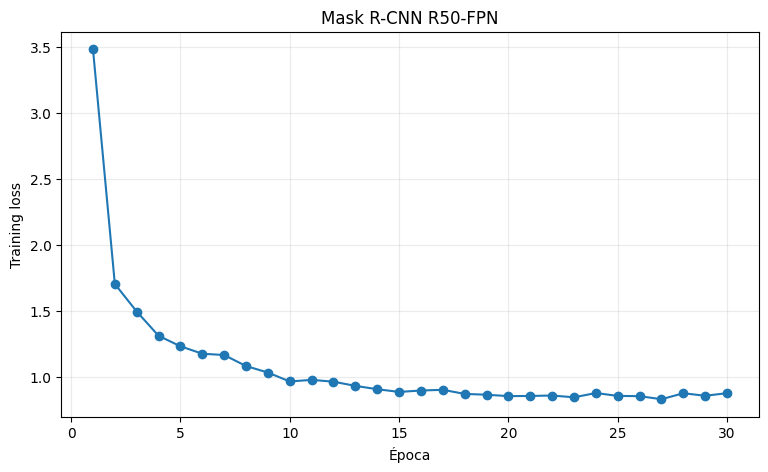

In [30]:
# Se grafica la pérdida registrada durante el entrenamiento para revisar su comportamiento.
plt.figure(figsize=(9,5))
plt.plot(history_df["epoch"],history_df["train_loss"],marker="o")
plt.xlabel("Época")
plt.ylabel("Training loss")
plt.title("Mask R-CNN R50-FPN")
plt.grid(alpha=.25)
plt.show()

### 3.16 Evaluación COCO en test

In [31]:
from pycocotools import mask as mask_utils

### 3.17 Métricas por instancia en test

In [32]:
# Se calculan precisión, recall, F1 e IoU con los umbrales definidos en el experimento.
CONF_THRESHOLD=0.50
IOU_THRESHOLD=0.50

def mask_iou(a,b):
    inter=np.logical_and(a,b).sum()
    union=np.logical_or(a,b).sum()
    return float(inter/union) if union else 0.0

def greedy_match(gt_masks,pred_masks,iou_thr=0.5):
    cand=[]
    for gi,g in enumerate(gt_masks):
        for pi,p in enumerate(pred_masks):
            i=mask_iou(g,p)
            if i>=iou_thr:
                cand.append((i,gi,pi))
    cand.sort(reverse=True,key=lambda x:x[0])
    ug,up=set(),set()
    vals=[]
    for i,gi,pi in cand:
        if gi not in ug and pi not in up:
            ug.add(gi); up.add(pi); vals.append(i)
    tp=len(vals)
    return tp,len(pred_masks)-tp,len(gt_masks)-tp,vals

TP=FP=FN=0
matched=[]

model.eval()
with torch.no_grad():
    for images,targets in tqdm(test_loader,desc="Métricas TEST"):
        image=images[0].to(device)
        out=model([image])[0]

        scores=out["scores"].cpu().numpy()
        keep=scores>=CONF_THRESHOLD
        pred_masks=(out["masks"].cpu().numpy()[keep,0]>=0.5)

        gt_masks=targets[0]["masks"].numpy().astype(bool)

        tp,fp,fn,vals=greedy_match(list(gt_masks),list(pred_masks),IOU_THRESHOLD)
        TP+=tp; FP+=fp; FN+=fn; matched.extend(vals)

precision=TP/(TP+FP) if TP+FP else 0
recall=TP/(TP+FN) if TP+FN else 0
f1=2*precision*recall/(precision+recall) if precision+recall else 0
mean_iou=float(np.mean(matched)) if matched else 0

metrics={
    "confidence_threshold":CONF_THRESHOLD,
    "iou_threshold":IOU_THRESHOLD,
    "TP":TP,"FP":FP,"FN":FN,
    "precision":precision,
    "recall":recall,
    "f1":f1,
    "mean_matched_iou":mean_iou
}

for k,v in metrics.items():
    print(f"{k:24s}: {v:.4f}" if isinstance(v,float) else f"{k:24s}: {v}")

Métricas TEST:   0%|          | 0/2 [00:00<?, ?it/s]

confidence_threshold    : 0.5000
iou_threshold           : 0.5000
TP                      : 62
FP                      : 20
FN                      : 2
precision               : 0.7561
recall                  : 0.9688
f1                      : 0.8493
mean_matched_iou        : 0.7474


### 3.18 Inspección de máscaras

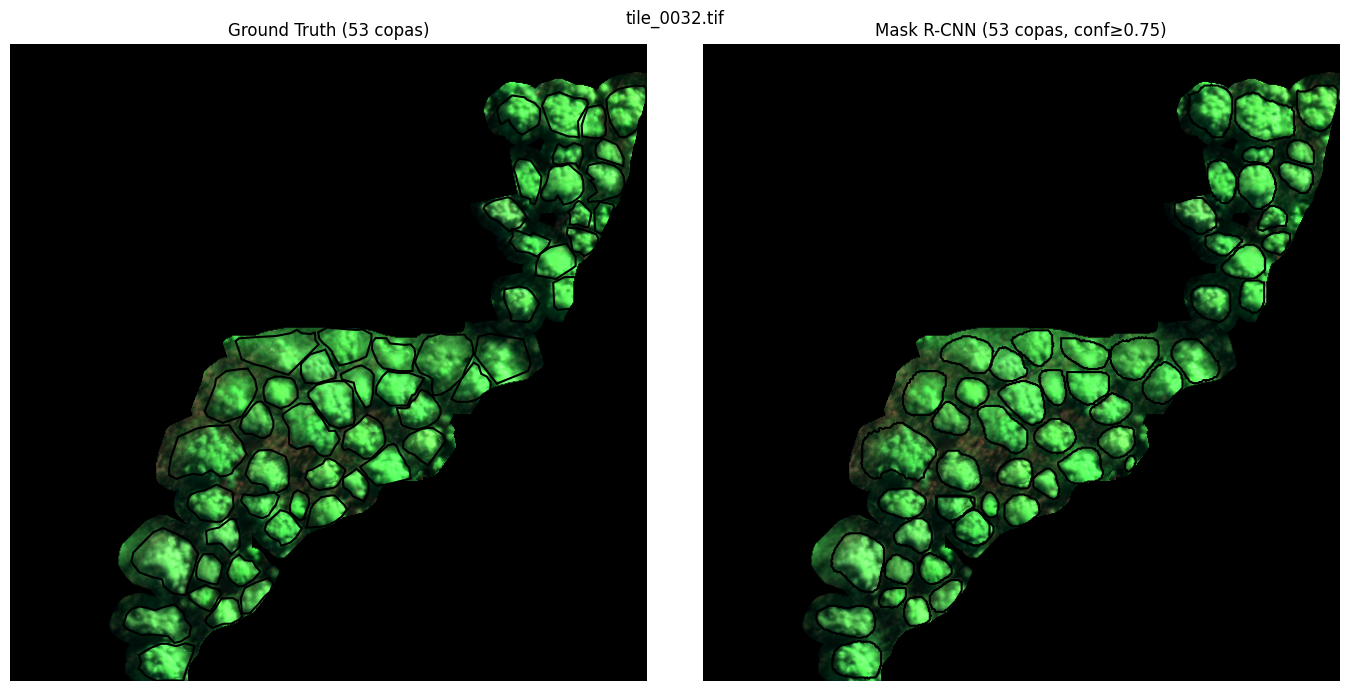

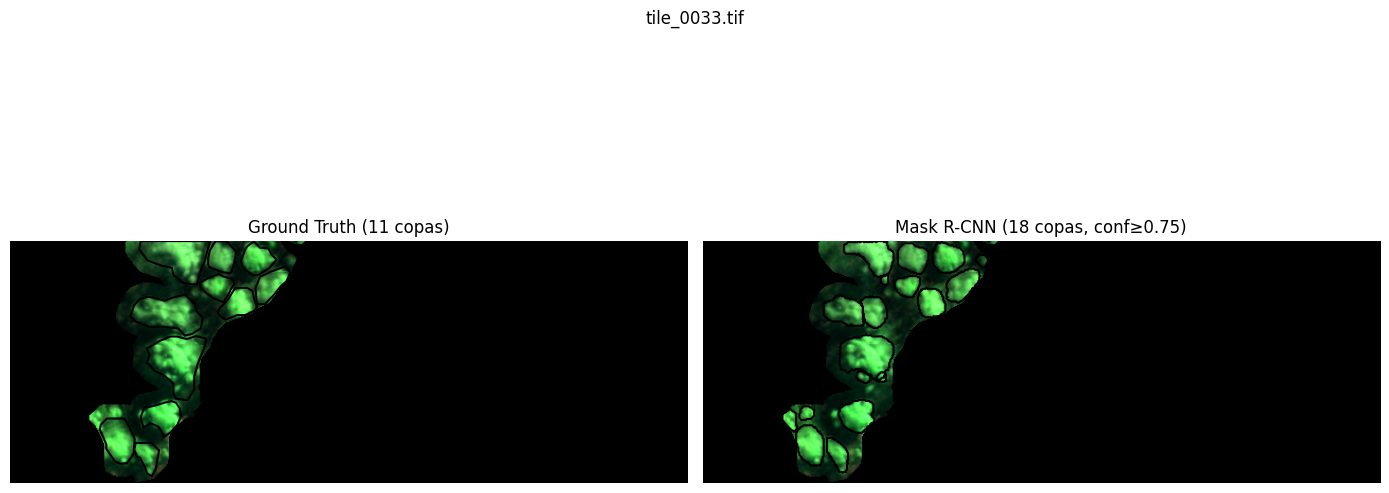

Guardadas en: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/resultados/mask_r-cnn/runs/mask_rcnn_R50_FPN_torchvision/visualizaciones_test


In [33]:
# Se comparan ejemplos de anotaciones reales y predicciones del modelo.
from matplotlib.patches import Polygon as MplPolygon
CONF_THRESHOLD = 0.75
VIS_DIR=OUTPUT_DIR/"visualizaciones_test"
VIS_DIR.mkdir(parents=True,exist_ok=True)

model.eval()

indices=np.linspace(0,len(test_ds)-1,min(10,len(test_ds)),dtype=int)

for idx in indices:
    image,target=test_ds[idx]
    info=test_ds.coco.loadImgs([test_ds.ids[idx]])[0]

    with torch.no_grad():
        out=model([image.to(device)])[0]

    rgb=image.permute(1,2,0).numpy()

    fig,axes=plt.subplots(1,2,figsize=(14,7))
    axes[0].imshow(rgb)

    ann_ids=test_ds.coco.getAnnIds(imgIds=[test_ds.ids[idx]])
    anns=test_ds.coco.loadAnns(ann_ids)
    for ann in anns:
        for seg in ann["segmentation"]:
            pts=np.asarray(seg).reshape(-1,2)
            axes[0].add_patch(MplPolygon(pts,closed=True,fill=False,linewidth=1.5))
    axes[0].set_title(f"Ground Truth ({len(anns)} copas)")
    axes[0].axis("off")

    axes[1].imshow(rgb)
    scores=out["scores"].cpu().numpy()
    keep=scores>=CONF_THRESHOLD
    pmasks=(out["masks"].cpu().numpy()[keep,0]>=0.5)

    for m in pmasks:
        contours,_=cv2.findContours(m.astype(np.uint8),cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
        for c in contours:
            if len(c)>=3:
                pts=c[:,0,:]
                axes[1].add_patch(MplPolygon(pts,closed=True,fill=False,linewidth=1.5))

    axes[1].set_title(f"Mask R-CNN ({len(pmasks)} copas, conf≥{CONF_THRESHOLD:.2f})")
    axes[1].axis("off")

    fig.suptitle(info["file_name"])
    plt.tight_layout()
    plt.savefig(VIS_DIR/f"{Path(info['file_name']).stem}_GT_vs_MaskRCNN.png",
                dpi=160,bbox_inches="tight")
    plt.show()

print("Guardadas en:",VIS_DIR)

### 3.19 Exportación de resultados de test

In [34]:
# Se guarda el resumen de evaluación del conjunto de prueba.
summary={
    "model":"torchvision maskrcnn_resnet50_fpn",
    "epochs":EPOCHS,
    "lr":LR,
    "batch_size":BATCH_SIZE,
    "tile_size":TILE_SIZE,
    "overlap":OVERLAP,
    "stride":STRIDE,
    "metrics_test":metrics
}
with open(OUTPUT_DIR/"results_summary.json","w") as f:
    json.dump(summary,f,indent=2)

print("Guardado:",OUTPUT_DIR/"results_summary.json")

Guardado: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/resultados/mask_r-cnn/runs/mask_rcnn_R50_FPN_torchvision/results_summary.json


## 4. Mask R-CNN | Evaluación censal completa

Se cargan los pesos entrenados, se ejecuta la inferencia sobre toda la ortofoto y se compara el resultado con el mismo censo evaluable y la misma máscara empleados por DeepForest. Esta evaluación es distinta de la evaluación COCO de la sección 3.

### 4.1 Carga de pesos y parámetros de inferencia

In [35]:
#Se reconstruye la arquitectura y se cargan los pesos guardados durante el entrenamiento. Los umbrales de inferencia son específicos de Mask R-CNN.
# Evaluación censal: reutilizar rutas, raster y censo de la preparación.
import gc
from rasterio.features import shapes
from shapely.geometry import shape
from torchvision.models.detection import maskrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor

RASTER = RUTA_PREPARADA
ORIGINAL = RUTA_TIF
CENSO = RUTA_SHP
PESOS = OUTPUT_DIR / "maskrcnn_final.pth"
SALIDA_FINAL = OUTPUT_DIR / "evaluacion_censal_definitiva"
SALIDA_FINAL.mkdir(parents=True, exist_ok=True)

# Parámetros de inferencia
TILE = 640
STRIDE = 512
CONF = 0.20
MASK_THR = 0.50
MIN_PIXELS = 15
NMS_IOU = 0.50
MIN_VALID_FRAC = 0.10

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Reconstruir arquitectura original
modelo_censo = maskrcnn_resnet50_fpn(
    weights=None,
    weights_backbone=None
)

n_cls = modelo_censo.roi_heads.box_predictor.cls_score.in_features

modelo_censo.roi_heads.box_predictor = FastRCNNPredictor(
    n_cls, 2
)

n_mask = modelo_censo.roi_heads.mask_predictor.conv5_mask.in_channels

modelo_censo.roi_heads.mask_predictor = MaskRCNNPredictor(
    n_mask, 256, 2
)

# Cargar pesos entrenados
estado = torch.load(
    PESOS, map_location="cpu", weights_only=True
)

modelo_censo.load_state_dict(estado, strict=True)
modelo_censo.to(DEVICE).eval()

print("Modelo entrenado cargado")
print("GPU:", DEVICE)
print("Raster:", RASTER)
print("TIFF original:", ORIGINAL)
print("Censo:", CENSO)
print("Pesos:", PESOS)

Modelo entrenado cargado
GPU: cuda
Raster: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/datos/Cerro_Alegre_Censo_Clip_uint8_global.tif
TIFF original: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/datos/Cerro_Alegre_Censo_Clip.tif
Censo: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/datos/Censo_CerroAlegre_parcelas_12-15-16.shp
Pesos: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/resultados/mask_r-cnn/runs/mask_rcnn_R50_FPN_torchvision/maskrcnn_final.pth


### 4.2 Referencias compartidas

In [36]:
# No se vuelven a generar ni la máscara ni el censo.
# Se utilizan los datos preparados al inicio del notebook.
censo_evaluable = censo_eval
censo_completo = censo_total

def puntos_en_mascara(geometrias, archivo_mascara):
    with rasterio.open(archivo_mascara) as msk:
        return np.array([
            bool(next(msk.sample([(g.x, g.y)]))[0] == 1)
            if g is not None and not g.is_empty else False
            for g in geometrias
        ], dtype=bool)

print("Censo evaluable compartido:", len(censo_evaluable))
print("Máscara compartida:", RUTA_MASCARA)


Censo evaluable compartido: 2682
Máscara compartida: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/datos/Cerro_Alegre_mascara_valida.tif


### 4.3 Inferencia y eliminación de duplicados

In [37]:
# La ortofoto se procesa por teselas superpuestas. Las máscaras se convierten en geometrías y se eliminan propuestas duplicadas mediante IoU.
# INFERENCIA COMPLETA MASK R-CNN
from tqdm.auto import tqdm

def posiciones(total, tam, paso):
    if total <= tam:
        return [0]
    p = list(range(0, total-tam+1, paso))
    if p[-1] != total-tam:
        p.append(total-tam)
    return sorted(set(p))

registros = []

with rasterio.open(RASTER) as src:
    assert src.crs == censo_evaluable.crs, (
        "CRS raster y censo incompatibles"
    )
    assert src.count >= 3
    assert all(t == "uint8" for t in src.dtypes[:3])

    xs = posiciones(src.width, TILE, STRIDE)
    ys = posiciones(src.height, TILE, STRIDE)

    total = len(xs)*len(ys)
    print("Teselas a revisar:", total)

    for y in tqdm(ys, desc="Filas"):
        for x in xs:
            w = min(TILE, src.width-x)
            h = min(TILE, src.height-y)
            ventana = Window(x, y, w, h)

            a = src.read([1,2,3],
                         window=ventana,
                         masked=True)

            invalida = np.ma.getmaskarray(a).any(axis=0)

            if (~invalida).mean() < MIN_VALID_FRAC:
                continue

            rgb = np.moveaxis(
                a.filled(0).astype(np.uint8), 0, -1
            )

            tensor = (
                torch.from_numpy(np.ascontiguousarray(rgb))
                .permute(2,0,1)
                .float()
                .div(255)
                .to(DEVICE)
            )

            with torch.inference_mode():
                out = modelo_censo([tensor])[0]

            tf = src.window_transform(ventana)

            scores = out["scores"].detach().cpu().numpy()
            labels = out["labels"].detach().cpu().numpy()
            masks = out["masks"].detach().cpu().numpy()

            for score, label, mask in zip(scores, labels, masks):
                if int(label) != 1 or float(score) < CONF:
                    continue

                binaria = mask[0] >= MASK_THR
                binaria[invalida] = False

                if binaria.sum() < MIN_PIXELS:
                    continue

                for geom, valor in shapes(
                    binaria.astype("uint8"),
                    mask=binaria,
                    transform=tf
                ):
                    if valor != 1:
                        continue

                    pol = shape(geom)

                    if pol.is_empty or pol.area <= 0:
                        continue

                    registros.append({
                        "score": float(score),
                        "geometry": pol
                    })

            del tensor, out, scores, labels, masks

print("Propuestas crudas:", len(registros))

# Deduplicación espacial por IoU
propuestas = gpd.GeoDataFrame(
    registros,
    columns=["score", "geometry"],
    geometry="geometry",
    crs=censo_evaluable.crs
)

propuestas = propuestas.sort_values(
    "score", ascending=False
).reset_index(drop=True)

# Agrupar candidatas con índice espacial.
# Se conservan primero las de mayor confianza.
elegidas = []
descartadas = set()

if len(propuestas):
    sidx = propuestas.sindex

    for i in tqdm(range(len(propuestas)), desc="Deduplicando"):
        if i in descartadas:
            continue

        g = propuestas.geometry.iloc[i]
        elegidas.append(i)

        for j in sidx.query(g, predicate="intersects"):
            j = int(j)

            if j <= i or j in descartadas:
                continue

            h = propuestas.geometry.iloc[j]
            union = g.union(h).area

            if union > 0:
                iou = g.intersection(h).area / union

                if iou >= NMS_IOU:
                    descartadas.add(j)

predicciones_unicas = (
    propuestas.iloc[elegidas]
    .copy()
    .reset_index(drop=True)
)

print("Detecciones únicas:", len(predicciones_unicas))
print("Inferencia completa terminada")

Teselas a revisar: 52


Filas:   0%|          | 0/13 [00:00<?, ?it/s]

Propuestas crudas: 3469


Deduplicando:   0%|          | 0/3469 [00:00<?, ?it/s]

Detecciones únicas: 2471
Inferencia completa terminada


### 4.4 Filtrado y evaluación frente al censo

In [38]:
# EVALUACIÓN CENSAL DEFINITIVA
# Filtrar predicciones según la máscara generada
validez_pred = puntos_en_mascara(
    predicciones_unicas.geometry.centroid,
    RUTA_MASCARA
)

pred_eval = (
    predicciones_unicas.loc[validez_pred]
    .copy()
    .reset_index(drop=True)
)

ref = censo_evaluable.copy().reset_index(drop=True)

ref["id_punto"] = np.arange(len(ref))
pred_eval["id_pred"] = np.arange(len(pred_eval))

# Mismo criterio que DeepForest: punto dentro de detección
if len(pred_eval):
    relaciones = gpd.sjoin(
        ref[["id_punto","geometry"]],
        pred_eval[["id_pred","geometry"]],
        predicate="within",
        how="inner"
    )
else:
    relaciones = pd.DataFrame(
        columns=["id_punto","id_pred","distancia"]
    )

matches = []

if len(relaciones):
    pts = ref.set_index("id_punto").geometry
    centros = pred_eval.set_index("id_pred").geometry.centroid

    relaciones["distancia"] = relaciones.apply(
        lambda r: pts.loc[r["id_punto"]].distance(
            centros.loc[r["id_pred"]]
        ),
        axis=1
    )

    relaciones = relaciones.sort_values("distancia")

    usados_gt = set()
    usados_pred = set()

    for _, r in relaciones.iterrows():
        i = int(r["id_punto"])
        j = int(r["id_pred"])

        if i not in usados_gt and j not in usados_pred:
            usados_gt.add(i)
            usados_pred.add(j)

            matches.append({
                "id_punto": i,
                "id_pred": j,
                "distancia_m": float(r["distancia"])
            })

TP = len(matches)
N_REAL = len(ref)
N_PRED = len(pred_eval)
FP = N_PRED-TP
FN = N_REAL-TP

precision = TP/(TP+FP) if TP+FP else 0.
recall = TP/(TP+FN) if TP+FN else 0.
f1 = 2*precision*recall/(precision+recall) if precision+recall else 0.

error_pct = 100*(N_PRED-N_REAL)/N_REAL

resultado = pd.DataFrame([{
    "modelo": "Mask R-CNN R50-FPN",
    "censo_evaluable": N_REAL,
    "detecciones": N_PRED,
    "TP": TP,
    "FP": FP,
    "FN": FN,
    "precision": precision,
    "recall": recall,
    "F1": f1,
    "error_conteo_pct": error_pct,
    "error_absoluto_pct": abs(error_pct)
}])

assert TP+FP == N_PRED
assert TP+FN == N_REAL

print("MASK R-CNN - RESULTADO CENSAL DEFINITIVO")
display(resultado.round(4))

# Guardar todos los resultados en carpeta nueva
resultado.to_csv(
    SALIDA_FINAL/"MASK_RCNN_METRICAS_CENSO.csv",
    index=False
)

pd.DataFrame(matches).to_csv(
    SALIDA_FINAL/"matches_censo.csv",
    index=False
)

ref.to_file(
    SALIDA_FINAL/"censo_evaluable.gpkg",
    driver="GPKG"
)

if len(pred_eval):
    pred_eval.to_file(
        SALIDA_FINAL/"detecciones_maskrcnn.gpkg",
        driver="GPKG"
    )

print("Resultados finales guardados en:", SALIDA_FINAL)

MASK R-CNN - RESULTADO CENSAL DEFINITIVO


,modelo,censo_evaluable,detecciones,TP,FP,FN,precision,recall,F1,error_conteo_pct,error_absoluto_pct
0,Mask R-CNN R50-FPN,2682,2471,1888,583,794,0.7641,0.704,0.7328,-7.8673,7.8673


Resultados finales guardados en: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/resultados/mask_r-cnn/runs/mask_rcnn_R50_FPN_torchvision/evaluacion_censal_definitiva


### 4.5 Visualización general

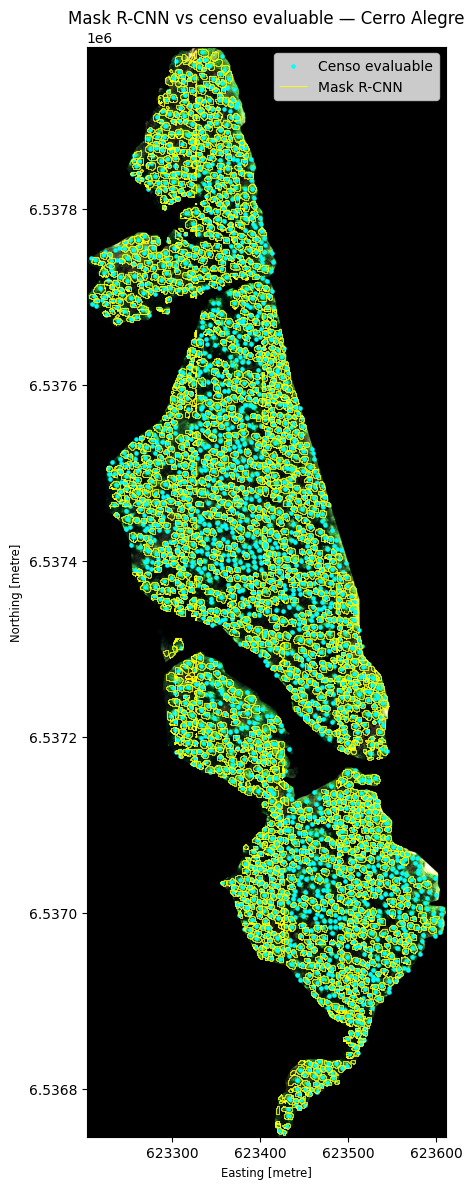

In [39]:
# Mapa general: MASK R-CNN VS CENSO
import matplotlib.pyplot as plt
import rasterio
import numpy as np

# Cargar raster para visualizar
with rasterio.open(RASTER) as src:
    rgb = src.read([1, 2, 3])
    rgb = np.moveaxis(rgb, 0, -1)
    bounds = src.bounds

fig, ax = plt.subplots(figsize=(12, 12))

ax.imshow(
    rgb,
    extent=(bounds.left, bounds.right, bounds.bottom, bounds.top)
)

# Censo evaluable
censo_evaluable.plot(
    ax=ax,
    color="cyan",
    markersize=5,
    label="Censo evaluable"
)

# Predicciones finales
if len(pred_eval):
    pred_eval.boundary.plot(
        ax=ax,
        color="yellow",
        linewidth=0.6,
        label="Mask R-CNN"
    )

ax.set_title("Mask R-CNN vs censo evaluable — Cerro Alegre")
ax.legend()
plt.tight_layout()
plt.show()

### 4.6 Visualización de aciertos y errores

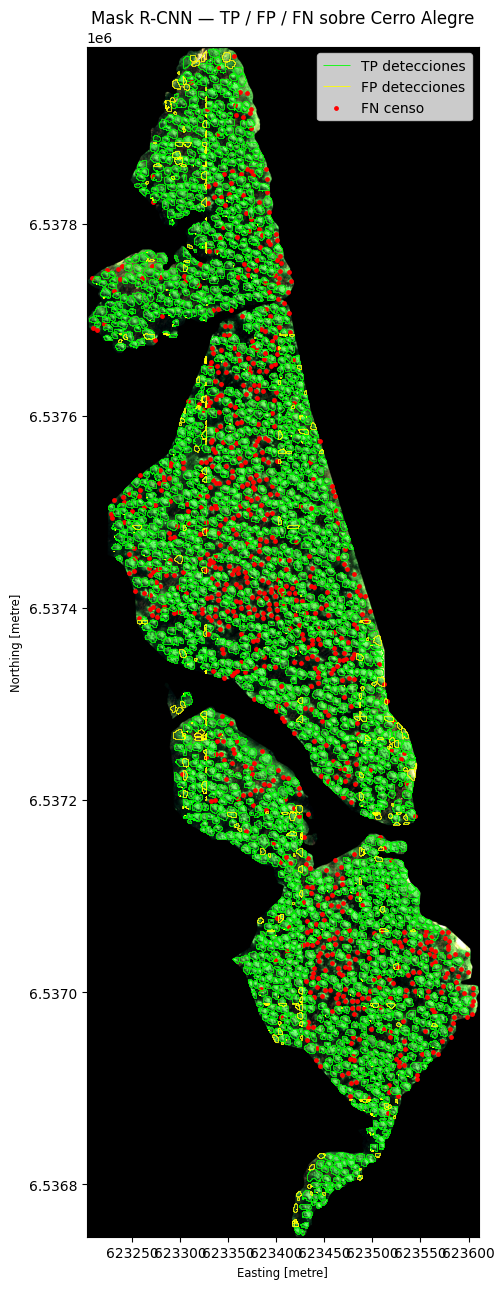

In [40]:
# Mapa de TP, FP y FN
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import rasterio
import numpy as np

# Reconstruir IDs si no existen
ref_plot = censo_evaluable.copy().reset_index(drop=True)
pred_plot = pred_eval.copy().reset_index(drop=True)

if "id_punto" not in ref_plot.columns:
    ref_plot["id_punto"] = np.arange(len(ref_plot))

if "id_pred" not in pred_plot.columns:
    pred_plot["id_pred"] = np.arange(len(pred_plot))

matches_df = pd.DataFrame(matches)

ids_tp_ref = set(matches_df["id_punto"]) if len(matches_df) else set()
ids_tp_pred = set(matches_df["id_pred"]) if len(matches_df) else set()

tp_ref = ref_plot[ref_plot["id_punto"].isin(ids_tp_ref)].copy()
fn_ref = ref_plot[~ref_plot["id_punto"].isin(ids_tp_ref)].copy()

tp_pred = pred_plot[pred_plot["id_pred"].isin(ids_tp_pred)].copy()
fp_pred = pred_plot[~pred_plot["id_pred"].isin(ids_tp_pred)].copy()

with rasterio.open(RASTER) as src:
    rgb = src.read([1, 2, 3])
    rgb = np.moveaxis(rgb, 0, -1)
    bounds = src.bounds

fig, ax = plt.subplots(figsize=(13, 13))

ax.imshow(
    rgb,
    extent=(bounds.left, bounds.right, bounds.bottom, bounds.top)
)

if len(tp_pred):
    tp_pred.boundary.plot(
        ax=ax, color="lime", linewidth=0.6, label="TP detecciones"
    )

if len(fp_pred):
    fp_pred.boundary.plot(
        ax=ax, color="yellow", linewidth=0.6, label="FP detecciones"
    )

if len(fn_ref):
    fn_ref.plot(
        ax=ax, color="red", markersize=6, label="FN censo"
    )

ax.set_title("Mask R-CNN — TP / FP / FN sobre Cerro Alegre")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Comparación de resultados

In [41]:
# Los resultados de ambas evaluaciones se presentan juntos.
comparacion = pd.DataFrame([
    {
        "Modelo": "DeepForest",
        "Censo evaluable": N_real_global,
        "Detecciones": N_pred_global,
        "TP": TP_global, "FP": FP_global, "FN": FN_global,
        "Precisión": precision_global, "Recall": recall_global,
        "F1": f1_global, "Error conteo (%)": error_conteo_global
    },
    {
        "Modelo": "Mask R-CNN",
        "Censo evaluable": N_REAL,
        "Detecciones": N_PRED,
        "TP": TP, "FP": FP, "FN": FN,
        "Precisión": precision, "Recall": recall,
        "F1": f1, "Error conteo (%)": error_pct
    }
])
display(comparacion.round(4))
comparacion.to_csv(DIRECTORIO_RESULTADOS / "Cerro_Alegre_comparacion.csv", index=False)


,Modelo,Censo evaluable,Detecciones,TP,FP,FN,Precisión,Recall,F1,Error conteo (%)
0,DeepForest,2682,2640,2340,300,342,0.8864,0.8725,0.8794,-1.5660
1,Mask R-CNN,2682,2471,1888,583,794,0.7641,0.7040,0.7328,-7.8673
